# EDA

Este notebook resume los analisis exploratorios principales del dataset de demanda electrica. El objetivo es entender la estructura de los perfiles diarios y detectar patrones relevantes para el modelo generativo condicionado.

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path
import os
import sys

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent

sys.path.append(str(project_root))

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

from src.data_quality import build_quality_summary
from src.daily_demand import (
    build_daily_demand_features,
    get_peak_hour_distribution,
    load_daily_model_data,
    plot_average_daily_profile,
    plot_daily_energy_series,
    plot_month_hour_heatmap,
    plot_peak_hour_distribution,
    plot_profile_by_day_type,
    summarize_by_day_type,
    summarize_by_month,
    summarize_daily_demand,
)

## 1. Calidad del dataset

Antes de analizar patrones de consumo, verificamos que los datasets diarios y horarios sean consistentes. Esta seccion busca confirmar que la base esta en condiciones de ser usada para el EDA y el modelado.

In [14]:
summary = build_quality_summary(project_root)

In [15]:
summary["missing_values"]

,dataset,rows,columns,missing_values
0,x_perfiles_diarios,1946,25,0
1,c_condiciones_diarias,1946,16,0
2,dataset_base_horario,46704,6,0
3,clima_efectivo_horario,46704,6,0


In [16]:
summary["value_ranges"]

,variable,min,max
0,demanda_mwh,9281.924,28094.100000
1,X_demanda_min,9281.924,28094.100000
2,temp_ef,-0.879,38.345000
3,humedad_ef,17.710,96.260000
4,viento_ef,1.860,31.657000
5,sensacion_ef,-4.516,39.331000
6,grado_calor,0.000,9.890583
7,grado_frio,0.000,12.235250


### Resultados principales

- El dataset diario de demanda `X` tiene 1.946 filas y 25 columnas: una fecha y 24 valores horarios de demanda.
- El dataset condicional `C` tiene 1.946 filas y 16 columnas: fecha, calendario y variables climaticas diarias.
- Los datasets horarios de demanda y clima tienen 46.704 filas cada uno, lo que coincide con 1.946 dias por 24 horas.
- El periodo cubierto va desde 2021-01-01 hasta 2026-04-30.
- No hay dias faltantes en el rango observado.
- Todos los dias tienen exactamente 24 registros horarios tanto en demanda como en clima.
- No se detectaron duplicados a nivel fecha-hora.
- No hay valores nulos en `X`, `C`, demanda horaria ni clima horario.
- Las fechas de `X` y `C` estan perfectamente alineadas.
- El dia bisiesto 2024-02-29 esta presente.
- La demanda horaria va de 9.281,924 MWh a 28.094,100 MWh.
- Las variables climaticas no muestran valores imposibles: la temperatura efectiva va de -0,879 C a 38,345 C, y la humedad efectiva va de 17,710% a 96,260%.
- El promedio diario de energia fue mayor en los primeros 30 dias de 2023 que en los ultimos 30 dias de 2022. Esto no alcanza por si solo para afirmar un problema de empalme, porque enero tiene un comportamiento estacional propio asociado al verano.
- En esta seccion trabajamos solo con los CSV ya preparados para el proyecto. Los Excel originales quedan como fuentes crudas y no son necesarios para correr el EDA inicial.

## 2. Demanda diaria

En esta seccion analizamos la demanda como perfiles diarios de 24 horas. El objetivo es describir el nivel de consumo, la forma promedio del perfil horario y las diferencias principales por calendario.

In [4]:
x_profiles, conditions = load_daily_model_data(project_root)
daily_demand = build_daily_demand_features(x_profiles, conditions)

daily_summary = summarize_daily_demand(daily_demand)
monthly_summary = summarize_by_month(daily_demand)
day_type_summary = summarize_by_day_type(daily_demand)
peak_hour_distribution = get_peak_hour_distribution(daily_demand)

daily_summary

,mean,std,min,25%,50%,75%,max
energia_diaria_mwh,381524.35,52673.41,272305.63,344390.13,372857.10,416526.48,555081.40
demanda_media_mwh,15896.85,2194.73,11346.07,14349.59,15535.71,17355.27,23128.39
demanda_maxima_mwh,18698.94,2591.61,13661.95,16818.65,18186.27,20355.18,28094.10
demanda_minima_mwh,12987.48,1688.36,9281.92,11774.75,12696.35,14082.37,19542.80
hora_pico,19.72,3.59,1.00,21.00,21.00,21.00,23.00
hora_valle,6.12,2.02,4.00,5.00,6.00,7.00,24.00
amplitud_diaria_mwh,5711.46,1339.18,2364.36,4783.88,5482.65,6488.49,11004.20
factor_carga,0.85,0.03,0.72,0.83,0.85,0.87,0.93


La tabla resume las variables diarias derivadas a partir de las 24 horas de demanda. La energia diaria promedio es de 381,5 GWh y la demanda maxima diaria promedio es de 18.699 MWh.

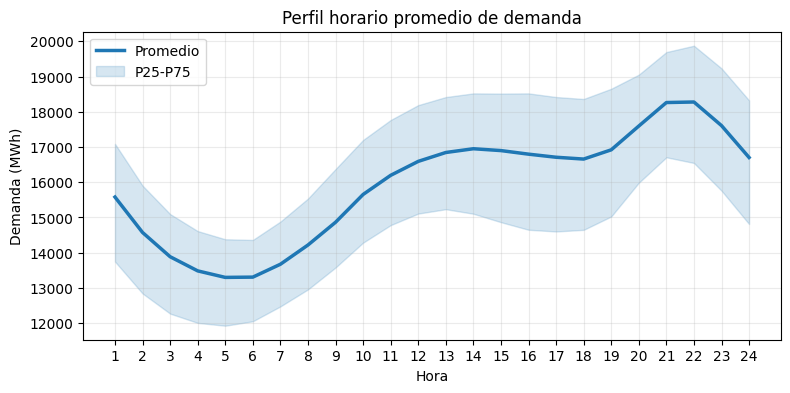

In [5]:
plot_average_daily_profile(daily_demand);

El perfil promedio muestra un valle durante la madrugada, con minimo alrededor de la hora 5, y un pico nocturno alrededor de las horas 21-22. Esta forma es importante para el modelo generativo: no alcanza con generar valores de demanda razonables, tambien hay que reproducir la estructura horaria del dia.

In [6]:
monthly_summary

,energia_media_gwh,demanda_maxima_media_mwh,hora_pico_mediana
mes,,,
1,421.74,20482.28,16.0
2,414.81,19997.79,17.0
3,384.30,18660.85,21.0
4,335.65,16489.00,21.0
5,365.73,18213.09,21.0
6,407.41,20286.21,21.0
7,410.73,20261.88,21.0
8,381.22,18825.36,21.0
9,350.13,17246.48,21.0


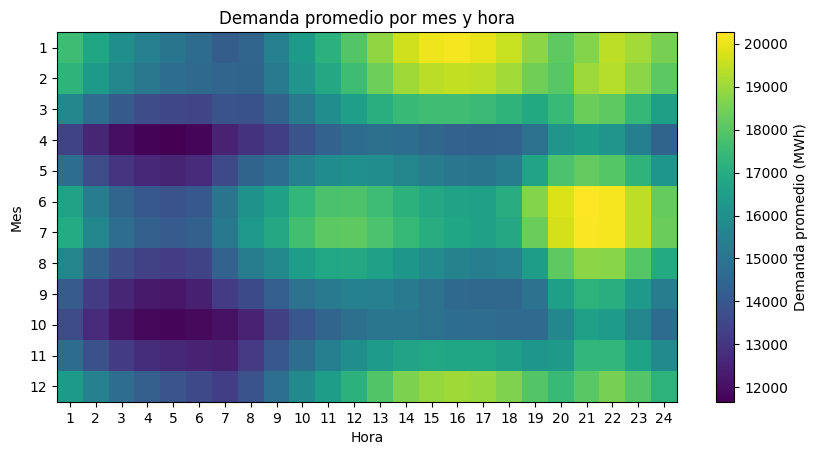

In [7]:
plot_month_hour_heatmap(daily_demand);

La demanda media diaria es mas alta en enero, febrero y julio, y mas baja en abril, octubre y septiembre. Esto sugiere una componente estacional marcada, consistente con mayor consumo en meses de calor y frio. Ademas, en enero, febrero y diciembre la mediana de la hora pico se adelanta hacia la tarde, mientras que en la mayoria de los meses se concentra a la noche.

In [8]:
day_type_summary

,dias,energia_media_gwh,demanda_maxima_media_mwh,factor_carga_medio
tipo_dia,,,,
habil,1309,396.39,19372.77,0.85
sabado,278,364.27,17591.41,0.86
domingo,278,339.16,17055.76,0.83
feriado,81,345.99,17250.28,0.84


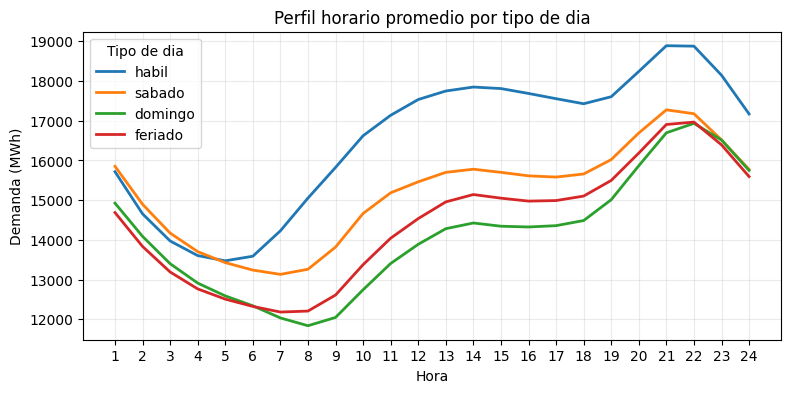

In [9]:
plot_profile_by_day_type(daily_demand);

Los dias habiles tienen mayor energia diaria promedio que sabados, domingos y feriados. Los domingos son el grupo de menor demanda media, aproximadamente 14% por debajo de los dias habiles. Esto confirma que el calendario no solo afecta el nivel de consumo, sino tambien la forma del perfil diario.

In [10]:
peak_hour_distribution.sort_values("dias", ascending=False).head(8)

,hora_pico,dias,porcentaje
8,21,1069,54.9
9,22,400,20.6
5,16,264,13.6
4,15,72,3.7
6,17,51,2.6
0,1,41,2.1
10,23,23,1.2
3,14,18,0.9


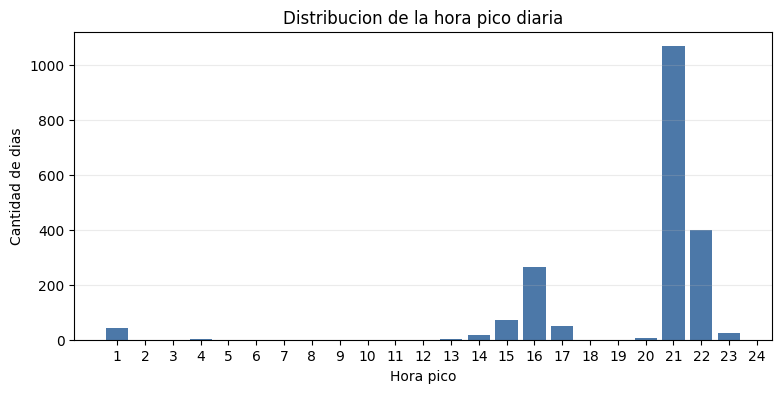

In [11]:
plot_peak_hour_distribution(daily_demand);

La hora pico diaria esta muy concentrada: la hora 21 explica 54,9% de los dias y la hora 22 explica 20,6%. En conjunto, tres de cada cuatro dias tienen su pico entre las 21 y las 22. Este patron deberia ser reproducido por los perfiles sinteticos.

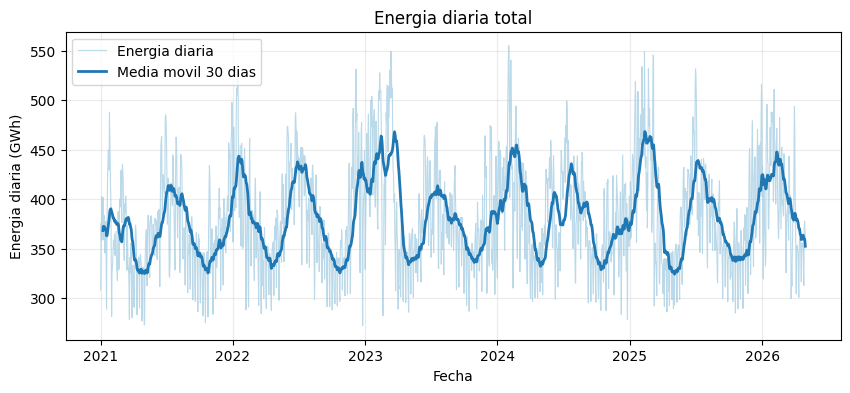

In [12]:
plot_daily_energy_series(daily_demand);

La serie temporal muestra variacion estacional y algunos dias extremos. El maximo de energia diaria se observa el 2024-02-01, con 555,1 GWh, mientras que el minimo ocurre el 2022-12-25, con 272,3 GWh. El minimo coincide con Navidad, por lo que parece un caso explicable por calendario. Tambien aparece el 2023-03-01 como dia de maxima amplitud diaria y mayor rampa horaria, por lo que conviene revisarlo luego junto con clima y eventos.